# 01 · Optimal dispatch in a basic network

In this tutorial you will build a three-node network with one load and three generators with fixed capacities (*non-extendable*): a wind farm, a solar PV park and a combined cycle gas turbine (CCGT). The optimisation resolves the power flow for a 24-hour period.

## 0. Import the required modules

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pypsa

pypsa.options.api.legacy_string_dtype = False  # keep pandas 3 string dtype (default from PyPSA 2.0); avoids a FutureWarning

## 1. Load the data

- `data.csv`: techno-economic parameters.
- `data_time_series.csv`: hourly capacity factors (`solar_CF`, `wind_CF`) and electricity demand (`demand_MW`).

In [2]:
### Load data.csv
params = pd.read_csv("data/data.csv", index_col="parameter")

# define a series with the values of the parameters for quick access
p = params["value"]

# show the parameters
params

,value,unit,description
parameter,,,
solar_p_nom,20.00,MW,Installed capacity of the solar PV park
solar_overnight_cost,600000.00,EUR/MW,Total (non-annualised) investment cost of sola...
solar_lifetime,25.00,years,Lifetime of solar PV
solar_marginal_cost,0.00,EUR/MWh,Operational cost of solar PV
wind_p_nom,20.00,MW,Installed capacity of the onshore wind park
wind_overnight_cost,1100000.00,EUR/MW,Total (non-annualised) investment cost of onsh...
wind_lifetime,25.00,years,Lifetime of onshore wind
wind_marginal_cost,5.00,EUR/MWh,Operational cost of onshore wind
ccgt_p_nom,50.00,MW,Installed capacity of the combined cycle gas t...


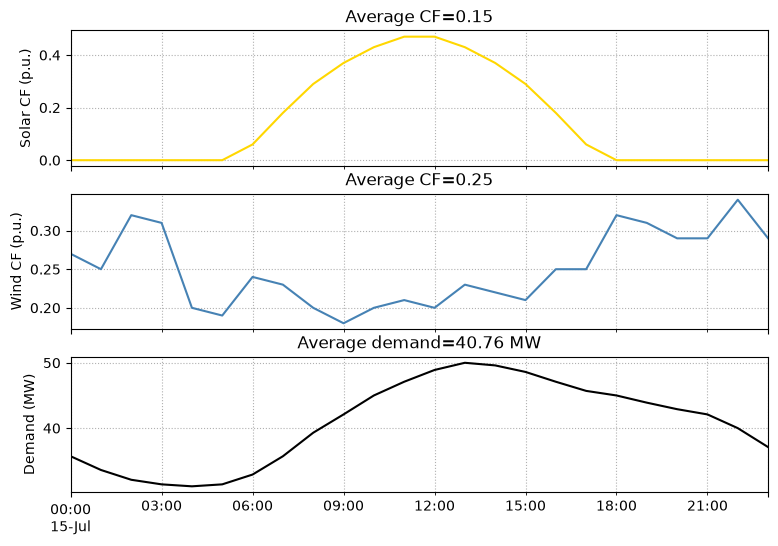

In [3]:
### Load data_time_series.csv
ts = pd.read_csv("data/data_time_series.csv", index_col="snapshot", parse_dates=True)

# Define a dict with the colors of each carrier (stored later in the network and used in all plots)
colors = {"solar": "gold",
          "wind": "steelblue",
          "gas": "indianred",
          "AC": "grey",
          "demand": "black"
}

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 6), sharex=True)

ts["solar_CF"].plot(ax=ax1, color=colors["solar"], ylabel="Solar CF (p.u.)", title=f"Average CF={ts["solar_CF"].mean():.2f}").grid(ls=":", which="both")
ts["wind_CF"].plot(ax=ax2, color=colors["wind"], ylabel="Wind CF (p.u.)", title=f"Average CF={ts["wind_CF"].mean():.2f}").grid(ls=":", which="both")
ts["demand_MW"].plot(ax=ax3, color=colors["demand"], ylabel="Demand (MW)", xlabel="", title=f"Average demand={ts["demand_MW"].mean():.2f} MW").grid(ls=":", which="both")

## 2. Create the network

Three buses aligned in a North-South direction, and two lines. *Carriers* identify each technology (`AC` for the lines, `demand` for the load) and store the colour used in all plots (`n.carriers.color`).

Line investment cost is defined per MW of capacity and km, so `overnight_cost` (EUR/MVA) = cost per MW·km × `length`.

In [4]:
n = pypsa.Network()

n.set_snapshots(ts.index)

n.add("Bus", ["North", "Center", "South"], x=[0, 0.2, 0], y=[2, 1, 0], v_nom=p["v_nom"])

n.add(
    "Line",
    ["North-Center", "South-Center"],
    bus0=["North", "South"],
    bus1=["Center", "Center"],
    x=p["line_x"],
    r=p["line_r"],
    s_nom=p["line_s_nom"],
    length=p["line_length"],
    overnight_cost=p["line_overnight_cost"] * p["line_length"],
    lifetime=p["line_lifetime"],
    discount_rate=p["discount_rate"],
)

n.add("Carrier", list(colors), color=list(colors.values()))

## 3. Add generators


Basic parameters:

- `p_nom`: installed capacity (MW), fixed (`p_nom_extendable=False`).
- `p_max_pu`: hourly capacity factor; limits output to `p_max_pu · p_nom`.
- `overnight_cost`: total, non-annualised investment cost (EUR/MW). PyPSA annualises it with `discount_rate` and `lifetime` and scales it to the modelled duration (24 h).
- `marginal_cost`: operational cost (EUR/MWh).

In [5]:
### Solar PV park (South bus)
n.add(
    "Generator",
    "Solar_South",
    bus="South",
    carrier="solar",
    p_nom=p["solar_p_nom"],
    p_nom_extendable=False,
    p_max_pu=ts["solar_CF"],
    overnight_cost=p["solar_overnight_cost"],
    lifetime=p["solar_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["solar_marginal_cost"],
)

### Wind farm (North bus)
n.add(
    "Generator",
    "Wind_North",
    bus="North",
    carrier="wind",
    p_nom=p["wind_p_nom"],
    p_nom_extendable=False,
    p_max_pu=ts["wind_CF"],
    overnight_cost=p["wind_overnight_cost"],
    lifetime=p["wind_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["wind_marginal_cost"],
)

### Combined cycle gas turbine (Center bus)
# Dispatchable: without `p_max_pu`, it can produce up to `p_nom` in every hour.
n.add(
    "Generator",
    "CCGT_Center",
    bus="Center",
    carrier="gas",
    p_nom=p["ccgt_p_nom"],
    p_nom_extendable=False,
    overnight_cost=p["ccgt_overnight_cost"],
    lifetime=p["ccgt_lifetime"],
    discount_rate=p["discount_rate"],
    marginal_cost=p["ccgt_marginal_cost"],
)

## 4. Add electricity demand

Basic parameters:

- `p_set`: imposed electricity demand (MW) in each snapshot.

In [6]:
n.add("Load",
      "Demand_Center",
      bus="Center",
      carrier="demand",
      p_set=ts["demand_MW"]
)

## 5. Optimisation

Minimises total system cost subject to the power balance at each bus and hour, the generator limits and the line capacities.

In [7]:
# io_api="direct" passes the model to HiGHS in memory; the default LP file fails silently with decimal-comma locales
n.optimize(solver_name="highs", io_api="direct")

/tmp/ipykernel_117119/2453018037.py:2: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", io_api="direct")
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 120 primals, 312 duals
Objective: 6.35e+04
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper were not assigned to the network.


Running HiGHS 1.15.1 (git hash: n/a): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP has 312 rows; 120 cols; 408 nonzeros
Coefficient ranges:
  Matrix  [1e+00, 1e+00]
  Cost    [5e+00, 8e+01]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 5e+01]
Presolving model
0 rows, 0 cols, 0 nonzeros 0s
0 rows, 0 cols, 0 nonzeros 0s
Presolve reductions: rows 0(-312); columns 0(-120); nonzeros 0(-408) - Reduced to empty
Performed postsolve
Solving the original LP from the solution after postsolve

Model status        : Optimal
Objective value     :  6.3504000000e+04
P-D objective error :  0.0000000000e+00
HiGHS run time      :          0.00


('ok', 'optimal')

## 6. Results

### Summary by technology



In [8]:
cols = ["Installed Capacity", "Optimal Capacity", "Supply", "Capacity Factor", "Curtailment"] 
n.statistics(components="Generator")[cols].round(2)

,Installed Capacity,Optimal Capacity,Supply,Capacity Factor,Curtailment
gas,50.0,50.0,786.3,0.66,413.7
solar,20.0,20.0,72.0,0.15,0.0
wind,20.0,20.0,120.0,0.25,0.0


### Hourly dispatch

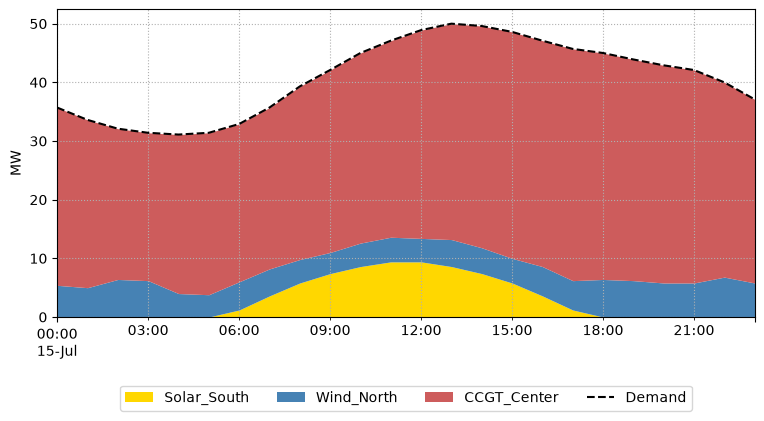

In [9]:
# Gather the dispatch of all generators
df_dispatch = n.generators_t.p

# Make a stacked area plot
ax = df_dispatch.plot.area(figsize=(9, 4), color=n.generators.carrier.map(n.carriers.color), lw=0, ylabel="MW", xlabel="")
n.loads_t.p_set["Demand_Center"].plot(ax=ax, color=n.carriers.color["demand"], ls="--", label="Demand", xlabel="")
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4);

### Line flows

Lines have two ports, `p0` and `p1`. According to the sign conventions (see https://docs.pypsa.org/latest/user-guide/design/#sign-conventions), `p0` is positive if the line is withdrawing power from `bus0`, and negative if it is injecting into the bus. Thus, positive `p0` values in this example represent power flows from North/South to Center node. The dotted line is the line capacity `s_nom`.

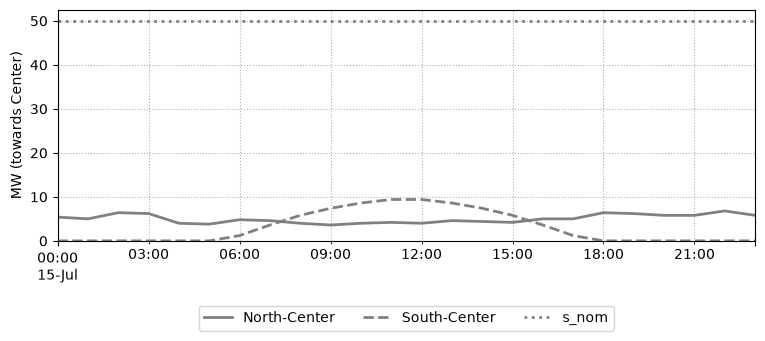

In [10]:
ac_color = n.carriers.color["AC"]

ax = n.lines_t.p0.plot(figsize=(9, 3), color=ac_color, style=["-", "--"], lw=2, ylabel="MW (towards Center)", xlabel="")
ax.axhline(p["line_s_nom"], color=ac_color, ls=":", lw=2, label="s_nom")
ax.set_ylim(bottom=0)
ax.grid(ls=":", which="both")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3);

### Nodal prices (EUR/MWh)

Dual variable of the power balance at each bus. The CCGT is the marginal technology in every hour and there is no congestion, so the price equals its marginal cost at all three buses (the three bars of each hour are equal).

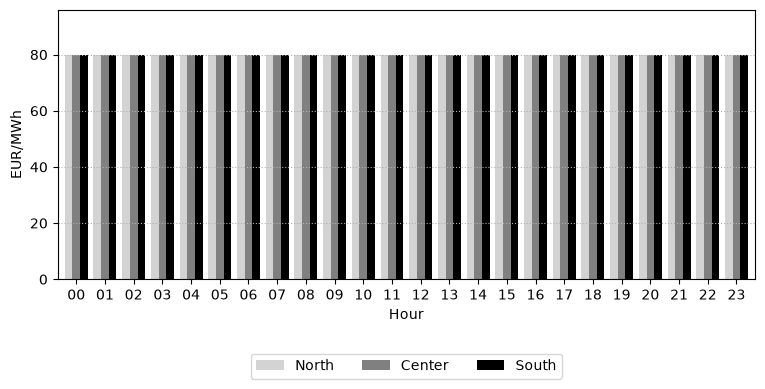

In [11]:
prices = n.buses_t.marginal_price

# Grouped bars per hour, one shade of grey per bus
ax = prices.set_axis(prices.index.strftime("%H"))[["North", "Center", "South"]].plot.bar(
    figsize=(9, 3.5), width=0.8, color=["lightgrey", "grey", "black"], ylabel="EUR/MWh", xlabel="Hour", rot=0
)
ax.set_ylim(0, 1.2 * prices.max().max())
ax.grid(ls=":", axis="y")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3);

### Cost analysis

Costs by carrier over the 24 modelled hours (EUR); lines are grouped under their carrier `AC`:

- **CAPEX**: investment annuity (from `overnight_cost`, `lifetime` and `discount_rate`) scaled to 24 h.
- **OPEX**: `marginal_cost` × dispatched energy.

In this example, lines only have CAPEX (no marginal cost).

In [12]:
cols = ["Capital Expenditure", "Operational Expenditure"]
n.statistics(components=["Generator", "Line"])[cols].round(2)

Capital Expenditure  Operational Expenditure
Generator gas                9935.31                  62904.0
          solar              2821.17                      0.0
          wind               5172.14                    600.0
Line      AC                  616.51                      0.0

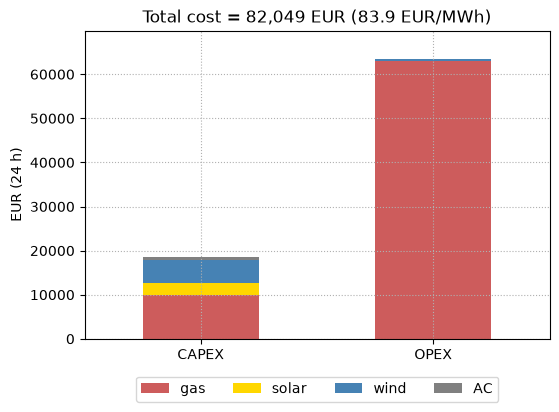

In [13]:
costs = pd.concat(
    {"CAPEX": n.statistics.capex(components=["Generator", "Line"]), "OPEX": n.statistics.opex(components=["Generator", "Line"])}, axis=1
).droplevel("component").fillna(0)

# Total cost and cost per MWh of demand
total_cost = costs.values.sum()
demand_MWh = n.loads_t.p_set.sum().sum()

ax = costs.T.plot.bar(stacked=True, figsize=(6, 4), color=costs.index.map(n.carriers.color), ylabel="EUR (24 h)", xlabel="", rot=0,
                      title=f"Total cost = {total_cost:,.0f} EUR ({total_cost / demand_MWh:.1f} EUR/MWh)")
ax.set_ylim(top=1.1 * costs.sum().max())
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
ax.grid(ls=":", which="both")


## 7. Final remarks

Choose a renewable technology (solar or wind) and repeat the analysis with increasing values of its installed capacity (`solar_p_nom` or `wind_p_nom` in `data.csv`):

- How does the optimal dispatch change?
- Is any energy curtailed? When and why?
- What happens to the nodal prices?
- Does the line capacity become a limiting factor?
- How do the total costs change, and their split between CAPEX and OPEX? And the cost per MWh?